In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, FancyArrowPatch
import matplotlib.patheffects as pe
from mpl_toolkits.mplot3d import proj3d

FIG = Path("figs")
DATA = FIG / "data"
OUTPUT = FIG / "Fig4.pdf"

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.7,
    "axes.grid": False,
    "figure.facecolor": "white",
    "savefig.bbox": None,
})

In [2]:
with np.load(DATA / "phase_portraits_fig4_data.npz") as saved:
    data = {key: saved[key] for key in saved.files}
with np.load(DATA / "fig4_b_VIII_g10p300000_g20p800000_n400_T70p000_dt0p0600_eps0p300.npz") as saved:
    basin = {key: saved[key] for key in saved.files}
with np.load(DATA / "phase_portraits_fig4_outflows.npz") as saved:
    outflow = {key: saved[key] for key in saved.files}

gamma1, gamma2 = float(data["g1"]), float(data["g2"])
grid = basin["grid"].astype(int)
basin_colors = basin["cmap_hex"].astype(str).tolist()
basin_cmap = ListedColormap(basin_colors)

t = data["distance_t"]
d_cluster = data["distance_to_cluster_attractor"]
d_saddles = data["distance_to_other_saddles"]

trajectory_points = outflow["trajectory_points"]
trajectory_offsets = outflow["trajectory_offsets"]
trajectories = [trajectory_points[start:stop]
                for start, stop in zip(trajectory_offsets[:-1], trajectory_offsets[1:])]


OUTFLOW_ARROW_COLOR = "#1E4ED8"


class _FlowArrow3D(FancyArrowPatch):

    def __init__(self, start, end, **kwargs):
        super().__init__((0, 0), (0, 0), **kwargs)
        self._endpoints = np.asarray([start, end])

    def do_3d_projection(self, renderer=None):
        x, y, z = proj3d.proj_transform(
            *self._endpoints.T, self.axes.get_proj())
        self.set_positions((x[0], y[0]), (x[1], y[1]))
        return float(np.min(z))

    def draw(self, renderer):
        self.do_3d_projection()
        super().draw(renderer)


def _draw_flow_arrow(ax, segment):
    arc = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(segment, axis=0), axis=1))]
    if arc[-1] < 1e-3:
        return
    endpoints = np.array([
        [np.interp(fraction * arc[-1], arc, segment[:, dim]) for dim in range(3)]
        for fraction in (0.28, 0.70)
    ])
    ax.add_artist(_FlowArrow3D(
        *endpoints, arrowstyle="-|>,head_length=0.42,head_width=0.20",
        mutation_scale=8.0, color=OUTFLOW_ARROW_COLOR, linewidth=1.05,
        shrinkA=0, shrinkB=0, zorder=13,
        path_effects=[pe.withStroke(linewidth=1.55, foreground="white")],
    ))

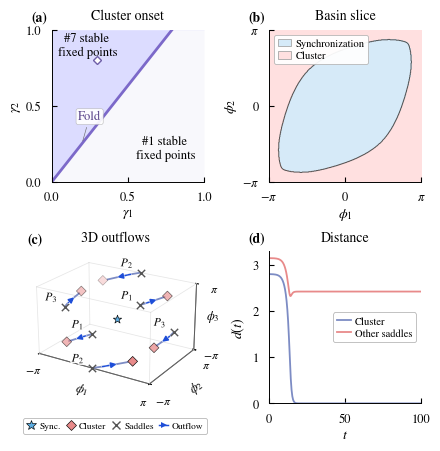

In [3]:
fig = plt.figure(figsize=(5.05, 5.05))
gs = fig.add_gridspec(
    2, 2, left=0.105, right=0.965, bottom=0.16, top=0.90,
    wspace=0, hspace=0.45,
)
ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[1, 0], projection="3d")
ax_d = fig.add_subplot(gs[1, 1])
ax_d.set_box_aspect(1)
panel_slots = [gs[row, col].get_position(fig) for row, col in [(0, 0), (0, 1), (1, 0), (1, 1)]]
c_left_shift = 0.025
c_slot = panel_slots[2].translated(-c_left_shift, 0)
panel_slots[2] = c_slot
ax_c.set_position([c_slot.x0, c_slot.y0 + 0.025, c_slot.width, c_slot.height - 0.025])

legend_style = dict(
    fontsize=7.6, frameon=True, facecolor="white", edgecolor="0.7",
    framealpha=0.94, borderpad=0.35, labelspacing=0.25,
    handlelength=1.3, handletextpad=0.4,
)

gamma1_axis = np.array([0.0, 1.0])
r_onset = float(data["r_onset"])
r_lo, r_hi = data["r_onset_ci"]
ax_a.fill_between(gamma1_axis, 0.0, r_lo * gamma1_axis, color="#F8F8FC", lw=0)
ax_a.fill_between(gamma1_axis, r_lo * gamma1_axis, r_hi * gamma1_axis, color="#F1F1FF", lw=0)
ax_a.fill_between(gamma1_axis, r_hi * gamma1_axis, 1.0, color="#DCDCFF", lw=0)
ax_a.plot(gamma1_axis, r_onset * gamma1_axis, color="#7C69C9", lw=2.0)
ax_a.plot(gamma1, gamma2, marker="D", ms=4.4, linestyle="None",
          markerfacecolor="white", markeredgecolor="#6F5FA8", markeredgewidth=1.0)
ax_a.text(0.74, 0.22, "#1 stable\n fixed points", fontsize=9, ha="center", va="center")
ax_a.text(0.23, 0.90, "#7 stable\n fixed points", fontsize=9, ha="center", va="center")
ax_a.annotate(
    "Fold", xy=(0.20, r_onset * 0.20), xytext=(0.25, 0.43),
    fontsize=9, color="#574188", ha="center", va="center",
    bbox=dict(boxstyle="round,pad=0.16", fc="white", ec="0.7", lw=0.4, alpha=0.92),
    arrowprops=dict(arrowstyle="-", color="0.42", lw=0.45),
)
ax_a.set(xlim=(0, 1), ylim=(0, 1), xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
ax_a.set_aspect("equal", adjustable="box")
ax_a.set_xlabel(r"$\gamma_1$", labelpad=2)
ax_a.set_ylabel(r"$\gamma_2$", labelpad=2)
ax_a.tick_params(direction="in", pad=7.0)

ax_b.imshow(grid, origin="lower", extent=basin["extent"], cmap=basin_cmap,
            vmin=0, vmax=2, aspect="equal", interpolation="nearest")
ax_b.contour(basin["phi1"], basin["phi2"], (grid == 1).astype(float),
             levels=[0.5], colors="0.28", linewidths=0.7, alpha=0.92)
ax_b.set_xticks([-np.pi, 0, np.pi], [r"$-\pi$", "0", r"$\pi$"])
ax_b.set_yticks([-np.pi, 0, np.pi], [r"$-\pi$", "0", r"$\pi$"])
ax_b.set_xlabel(r"$\phi_1$", labelpad=2)
ax_b.set_ylabel(r"$\phi_2$", labelpad=2)
ax_b.tick_params(direction="in", pad=7.0)
basin_legend = ax_b.legend(handles=[
    Patch(facecolor=basin_colors[0], edgecolor="0.65",linewidth=0.6, label="Synchronization"),
    Patch(facecolor=basin_colors[1], edgecolor="0.65",linewidth=0.6, label="Cluster"),
], loc="upper left", **legend_style)
basin_legend.get_frame().set_linewidth(0.6)

ax_c.computed_zorder = False
L = np.pi
for varying_axis in range(3):
    fixed_axes = [axis for axis in range(3) if axis != varying_axis]
    for first in (-L, L):
        for second in (-L, L):
            edge = np.zeros((2, 3))
            edge[:, varying_axis] = [-L, L]
            edge[:, fixed_axes[0]] = first
            edge[:, fixed_axes[1]] = second
            ax_c.plot(*edge.T, color="0.82", lw=0.55, alpha=0.55)

in_phase = data["in_phase"]
sinks = data["cluster_sinks"]
display_saddles = outflow["display_saddle_points"]
ax_c.scatter(*in_phase.T, marker="*", color="#5DADE2", s=40,
             edgecolor="black", linewidth=0.45, zorder=10)
ax_c.scatter(*sinks.T, marker="D", color="#E88A8A", s=25,
             edgecolor="black", linewidth=0.45, zorder=10)
ax_c.scatter(*display_saddles.T, marker="x", color="#555555", s=28,
             linewidths=1.0, zorder=11, depthshade=False)
for point, label in zip(display_saddles, outflow["display_saddle_labels"]):
    ax_c.text(point[0] - 0.28, point[1] - 0.28, point[2] + 0.28, str(label),
              fontsize=8.5, color="#111", zorder=12, ha="right", va="bottom",
              path_effects=[pe.withStroke(linewidth=2.2, foreground="white", alpha=0.92)])

for trajectory in trajectories:
    cuts = np.where(np.linalg.norm(np.diff(trajectory, axis=0), axis=1) > np.pi)[0]
    for segment in np.split(trajectory, cuts + 1):
        if len(segment) < 5:
            continue
        ax_c.plot(*segment.T, color="#7D8CC4", lw=1.3, alpha=1.0, zorder=9)
        _draw_flow_arrow(ax_c, segment)

for axis in (ax_c.xaxis, ax_c.yaxis, ax_c.zaxis):
    axis.pane.set_facecolor((1, 1, 1, 0))
    axis.pane.set_edgecolor((1, 1, 1, 0))
ax_c.grid(False)
ax_c.set(xlim=(-L, L), ylim=(-L, L), zlim=(-L, L))
ax_c.set_xticks([-L, L], [r"$-\pi$", r"$\pi$"])
ax_c.set_yticks([-L, L], [r"$-\pi$", r"$\pi$"])
ax_c.set_zticks([-L, L], [r"$-\pi$", r"$\pi$"])
ax_c.set_xlabel(r"$\phi_1$", labelpad=-10, fontsize=9)
ax_c.set_ylabel(r"$\phi_2$", labelpad=-10, fontsize=9)
ax_c.zaxis.set_rotate_label(False)
ax_c.set_zlabel(r"$\phi_3$", labelpad=-15, fontsize=9, rotation=0)
ax_c.tick_params(labelsize=8.5, pad=-2)
ax_c.view_init(elev=22, azim=-58)
ax_c.set_box_aspect((1.40, 1.00, 0.78), zoom=1.2)
legend_bottom = ax_d.get_position().y0
legend_downshift = 0.06
geometry_legend = ax_c.legend(handles=[
    Line2D([], [], marker="*", linestyle="None", color="#5DADE2", markeredgecolor="black", markeredgewidth=0.45, markersize=7, label="Sync."),
    Line2D([], [], marker="D", linestyle="None", color="#E88A8A", markeredgecolor="black", markeredgewidth=0.45, markersize=5, label="Cluster"),
    Line2D([], [], marker="x", linestyle="None", color="#555555", markersize=6, label="Saddles"),
    Line2D([], [], color=OUTFLOW_ARROW_COLOR, lw=1.05, marker=">", markersize=4, markeredgewidth=0, label="Outflow"),
], loc="lower center", ncol=4,
    bbox_to_anchor=((c_slot.x0 + c_slot.x1) / 2, legend_bottom - legend_downshift),
    bbox_transform=fig.transFigure, borderaxespad=0,
    columnspacing=0.5,
    **(legend_style | {"fontsize": 6.8, "handlelength": 1.0}))
geometry_legend.get_frame().set_linewidth(0.6)

for artist in [*ax_c.lines, *ax_c.collections, *ax_c.patches]:
    artist.set_clip_on(False)

ax_d.plot(t, d_cluster, color="#7D8CC4", lw=1.3, label="Cluster")
ax_d.plot(t, d_saddles, color="#E88A8A", lw=1.3, label="Other saddles")
ax_d.set_xlim(0, 100)
ax_d.set_ylabel(r'$d(t)$')
ax_d.set_ylim(0, max(d_cluster.max(), d_saddles.max()) * 1.05)
ax_d.set_xticks([0, 50, 100])
ax_d.set_yticks([0, 1, 2, 3])
ax_d.set_xlabel(r"$t$", labelpad=2)
ax_d.tick_params(direction="in", pad=7.0)
distance_legend = ax_d.legend(loc="center right", **legend_style)
distance_legend.get_frame().set_linewidth(0.6)

for axis, label in zip((ax_a, ax_b, ax_c, ax_d), "abcd"):
    write = axis.text2D if axis is ax_c else axis.text
    write(-0.13, 1.04, f"({label})", transform=axis.transAxes,
          fontsize=9.8, fontweight="bold", ha="left", va="bottom", clip_on=False)
for slot, title in zip(panel_slots, ["Cluster onset", "Basin slice", "3D outflows", r"Distance"]):
    fig.text((slot.x0 + slot.x1) / 2, slot.y1 + 0.020, title,
             fontsize=10, ha="center", va="baseline")

fig.savefig(OUTPUT, bbox_inches="tight", facecolor="white", pad_inches=0)
plt.show()